In [ ]:
!pip install pandas nltk

import pandas as pd
import re
import nltk

from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("averaged_perceptron_tagger_eng")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [ ]:
df = pd.read_csv("/content/complaints-dataset.csv",
    low_memory=False)

print("Dataset shape:", df.shape)
print(df.columns.tolist())

df.head()

Dataset shape: (93626, 15)
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2026-07-08T03:52:15.000Z,Credit card,Store credit card,Getting a credit card,Card opened without my consent or knowledge,Company has responded to the consumer and the ...,SYNCHRONY FINANCIAL,GA,30122,Servicemember,Web,2026-07-08T04:42:27.000Z,Closed with explanation,Yes,23970492
1,2026-07-28T00:37:37.000Z,Credit card,Store credit card,Fees or interest,Charged too much interest,Company has responded to the consumer and the ...,SYNCHRONY FINANCIAL,NJ,08107,NaN,Web,2026-07-28T13:48:15.000Z,Closed with monetary relief,No,24660085
2,2026-08-06T02:03:42.000Z,Credit card,General-purpose credit card or charge card,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,Company has responded to the consumer and the ...,"BANK OF AMERICA, NATIONAL ASSOCIATION",CA,91201,NaN,Web,2026-08-06T02:14:02.000Z,Closed with monetary relief,Yes,25014569
3,2026-08-01T23:36:10.000Z,Credit card,General-purpose credit card or charge card,Problem with a purchase shown on your statement,Card was charged for something you did not pur...,Company has responded to the consumer and the ...,"BANK OF AMERICA, NATIONAL ASSOCIATION",CA,90012,NaN,Web,2026-08-01T23:47:57.000Z,Closed with monetary relief,Yes,24858656
4,2026-07-31T15:36:49.000Z,Credit card,General-purpose credit card or charge card,"Other features, terms, or problems",Problem with balance transfer,NaN,Chime Financial Inc,GA,30135,NaN,Web,2026-07-31T15:50:22.000Z,Closed with explanation,Yes,24815374


In [ ]:
df["original_text"] = (
    df["Issue"].fillna("") + " " +
    df["Sub-issue"].fillna("")
).str.strip()

df = df[df["original_text"] != ""].copy()

df[["Issue", "Sub-issue", "original_text"]].head()


,Issue,Sub-issue,original_text
0,Getting a credit card,Card opened without my consent or knowledge,Getting a credit card Card opened without my c...
1,Fees or interest,Charged too much interest,Fees or interest Charged too much interest
2,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,Problem with a purchase shown on your statemen...
3,Problem with a purchase shown on your statement,Card was charged for something you did not pur...,Problem with a purchase shown on your statemen...
4,"Other features, terms, or problems",Problem with balance transfer,"Other features, terms, or problems Problem wit..."


In [ ]:
# 1. Lowercasing
df["lowercase_text"] = df["original_text"].str.lower()

# 2. Remove special characters and punctuation
def remove_special_characters(text):
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["normalized_text"] = df["lowercase_text"].apply(
    remove_special_characters
)

# 3. Tokenization
df["tokens"] = df["normalized_text"].apply(
    lambda text: text.split()
)

# 4. Stop-word removal
stop_words = set(stopwords.words("english"))

# Keep negations important for sentiment analysis
stop_words -= {"no", "not", "nor"}

df["filtered_tokens"] = df["tokens"].apply(
    lambda words: [
        word for word in words
        if word not in stop_words
    ]
)

# 5. Lemmatization
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

def lemmatize_words(words):
    tagged = nltk.pos_tag(words)

    return [
        lemmatizer.lemmatize(
            word, get_wordnet_pos(tag)
        )
        for word, tag in tagged
    ]

df["lemmatized_tokens"] = df["filtered_tokens"].apply(
    lemmatize_words
)

df["cleaned_text"] = df["lemmatized_tokens"].apply(
    lambda words: " ".join(words)
)

print(df[["original_text", "cleaned_text"]].head())

                                       original_text  \
0  Getting a credit card Card opened without my c...   
1         Fees or interest Charged too much interest   
2  Problem with a purchase shown on your statemen...   
3  Problem with a purchase shown on your statemen...   
4  Other features, terms, or problems Problem wit...   

                                        cleaned_text  
0  get credit card card open without consent know...  
1                  fee interest charge much interest  
2  problem purchase show statement credit card co...  
3  problem purchase show statement card charge so...  
4      feature term problem problem balance transfer  


In [ ]:

# Select the columns for your submission
result = df[
    [
        "Complaint ID",
        "Product",
        "Issue",
        "Sub-issue",
        "original_text",
        "lowercase_text",
        "normalized_text",
        "tokens",
        "filtered_tokens",
        "lemmatized_tokens",
        "cleaned_text"
    ]
].copy()

# Save the cleaned data
result.to_csv(
    "CFPB_Cleaned_Data.csv",
    index=False
)

print("Cleaning complete!")
print("Records processed:", len(result))

result.head(10)

Cleaning complete!
Records processed: 93626


,Complaint ID,Product,Issue,Sub-issue,original_text,lowercase_text,normalized_text,tokens,filtered_tokens,lemmatized_tokens,cleaned_text
0,23970492,Credit card,Getting a credit card,Card opened without my consent or knowledge,Getting a credit card Card opened without my c...,getting a credit card card opened without my c...,getting a credit card card opened without my c...,"[getting, a, credit, card, card, opened, witho...","[getting, credit, card, card, opened, without,...","[get, credit, card, card, open, without, conse...",get credit card card open without consent know...
1,24660085,Credit card,Fees or interest,Charged too much interest,Fees or interest Charged too much interest,fees or interest charged too much interest,fees or interest charged too much interest,"[fees, or, interest, charged, too, much, inter...","[fees, interest, charged, much, interest]","[fee, interest, charge, much, interest]",fee interest charge much interest
2,25014569,Credit card,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,Problem with a purchase shown on your statemen...,problem with a purchase shown on your statemen...,problem with a purchase shown on your statemen...,"[problem, with, a, purchase, shown, on, your, ...","[problem, purchase, shown, statement, credit, ...","[problem, purchase, show, statement, credit, c...",problem purchase show statement credit card co...
3,24858656,Credit card,Problem with a purchase shown on your statement,Card was charged for something you did not pur...,Problem with a purchase shown on your statemen...,problem with a purchase shown on your statemen...,problem with a purchase shown on your statemen...,"[problem, with, a, purchase, shown, on, your, ...","[problem, purchase, shown, statement, card, ch...","[problem, purchase, show, statement, card, cha...",problem purchase show statement card charge so...
4,24815374,Credit card,"Other features, terms, or problems",Problem with balance transfer,"Other features, terms, or problems Problem wit...","other features, terms, or problems problem wit...",other features terms or problems problem with ...,"[other, features, terms, or, problems, problem...","[features, terms, problems, problem, balance, ...","[feature, term, problem, problem, balance, tra...",feature term problem problem balance transfer
5,25161325,Credit card,Fees or interest,Charged too much interest,Fees or interest Charged too much interest,fees or interest charged too much interest,fees or interest charged too much interest,"[fees, or, interest, charged, too, much, inter...","[fees, interest, charged, much, interest]","[fee, interest, charge, much, interest]",fee interest charge much interest
6,25121714,Credit card,Problem with a purchase shown on your statement,Overcharged for something you did purchase wit...,Problem with a purchase shown on your statemen...,problem with a purchase shown on your statemen...,problem with a purchase shown on your statemen...,"[problem, with, a, purchase, shown, on, your, ...","[problem, purchase, shown, statement, overchar...","[problem, purchase, show, statement, overcharg...",problem purchase show statement overcharge som...
7,25437697,Credit card,Fees or interest,Charged too much interest,Fees or interest Charged too much interest,fees or interest charged too much interest,fees or interest charged too much interest,"[fees, or, interest, charged, too, much, inter...","[fees, interest, charged, much, interest]","[fee, interest, charge, much, interest]",fee interest charge much interest
8,25422922,Credit card,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,Problem with a purchase shown on your statemen...,problem with a purchase shown on your statemen...,problem with a purchase shown on your statemen...,"[problem, with, a, purchase, shown, on, your, ...","[problem, purchase, shown, statement, credit, ...","[problem, purchase, show, statement, credit, c...",problem purch

In [ ]:
# Validate the cleaned dataset
required_columns = [
    "original_text",
    "normalized_text",
    "tokens",
    "filtered_tokens",
    "lemmatized_tokens",
    "cleaned_text"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("Dataset validation successful")
print("Total records:", len(df))
print("Empty cleaned records:",
      (df["cleaned_text"].str.strip() == "").sum())

print("\nSample transformations:")
print(
    df[["original_text", "cleaned_text"]]
    .head(10)
    .to_string(index=False)
)


Dataset validation successful
Total records: 93626
Empty cleaned records: 0

Sample transformations:
                                                                                                                   original_text                                                                           cleaned_text
                                                               Getting a credit card Card opened without my consent or knowledge                                    get credit card card open without consent knowledge
                                                                                      Fees or interest Charged too much interest                                                      fee interest charge much interest
Problem with a purchase shown on your statement Credit card company isn't resolving a dispute about a purchase on your statement problem purchase show statement credit card company resolve dispute purchase statement
               Problem with a purch

Words before cleaning: 1233955
Words after cleaning: 737367
Word reduction: 40.24%


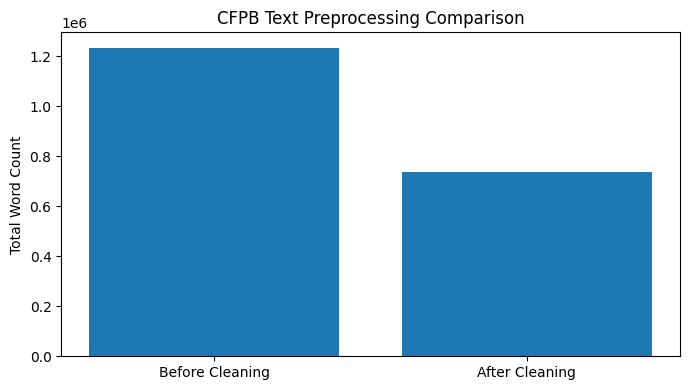

In [ ]:
import matplotlib.pyplot as plt

# Compare word counts before and after cleaning
df["words_before"] = df["original_text"].apply(
    lambda text: len(str(text).split())
)

df["words_after"] = df["cleaned_text"].apply(
    lambda text: len(str(text).split())
)

before = df["words_before"].sum()
after = df["words_after"].sum()

print("Words before cleaning:", before)
print("Words after cleaning:", after)

if before > 0:
    reduction = (before - after) / before * 100
    print(f"Word reduction: {reduction:.2f}%")

plt.figure(figsize=(7, 4))
plt.bar(
    ["Before Cleaning", "After Cleaning"],
    [before, after]
)

plt.title("CFPB Text Preprocessing Comparison")
plt.ylabel("Total Word Count")
plt.tight_layout()
plt.show()

In [ ]:
required_input = ["Complaint ID", "Product", "Issue", "Sub-issue"]

missing = [
    col for col in required_input
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing input columns: {missing}")

if df["Complaint ID"].duplicated().any():
    raise ValueError("Duplicate Complaint IDs detected")

print("Input validation passed")

Input validation passed
